# Hessian to Morse bonding potentials parametrization

Parametrizes a Morse potential (`D_e`, `a`, `r_e`) for every shell of every basis site, using the Hessian of an empirical pair-potential.

Pipeline:

1. Generate supercells with symmetry-reduced displacements at the unstrained (reference) volume and at several strained volumes.
2. Evaluate forces on every supercell.
3. Build a Hessian per volume from those forces.
4. Fit `D_e`/`a` per shell against the reference + strained Hessians (joint fit).
5. Save the result to `morse_parameters/<formula>_<crystal>.json`.

This notebook lives at `examples/hessian_to_morse_parametrization/`, with structures under `examples/structures/<formula>_<crystal>/`, potential files under `examples/potentials/<potential_formula>/` and outputs written to `morse_parameters/` alongside this notebook.

Runtime: about one minute for the default Al (fcc) settings on a laptop.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from ase.calculators.eam import EAM
from ase.io import read

import mean_field_bond_model.hessian as mf_hessian
import mean_field_bond_model.morse as mf_morse

## Settings

Adjust the paths and formula + crystal label to match the structure and potential you're parametrizing.

In [2]:
formula = "Al"
crystal = "fcc"
potential_formula = "Al"
potential_name = "Al1.eam.fs"

prefix = f"{formula}_{crystal}"
structure_path = Path(f"../structures/{prefix}/{prefix}.data")
potential_path = Path(f"../potentials/{potential_formula}/{potential_name}")
output_dir = Path("morse_parameters/")
output_dir.mkdir(exist_ok=True)
# The shipped morse_parameters/*.json files are the ones the pre-computed
# Morse Hessians and MD reference data in examples/ were generated with.
# Set overwrite = True to replace them with the parameters fitted here.
overwrite = False

n_shells = 3
supercell = 5
# isotropic strains evenly spaced in [-strain, strain]
strain = 0.07
# an even n_strains avoids an exact-zero (redundant) strain point,
# but an odd one is more accurate here
n_strains = 7

## Load the structure and calculator

In [3]:
structure = read(structure_path, format="lammps-data")
calc = EAM(potential=str(potential_path))


def get_forces(atoms_list):
    """
    Evaluate forces on a list of ase.Atoms, reusing the same calculator.
    """
    forces = []
    for atoms in atoms_list:
        atoms.calc = calc
        forces.append(atoms.get_forces())
    return forces

## Reference (unstrained) volume

In [4]:
ref_displaced, ref_disp_dict, ref_phonopy = (
    mf_hessian.generate_supercells_with_displacements(
        structure=structure,
        supercell=supercell,
        return_phonopy=True,
    )
)

ref_forces = get_forces(ref_displaced)

ref_hessian = mf_hessian.compute_hessian(
    forces=ref_forces,
    displacement_dict=ref_disp_dict,
    phonopy=ref_phonopy,
)

## Strained volumes

In [5]:
strained_structures = mf_hessian.generate_strained_structures(
    structure=structure,
    strain=strain,
    n_strains=n_strains,
)

# This can take a while: it can generate many displaced structures
strained_results = mf_hessian.generate_displacements_for_structures(
    structures=strained_structures,
    supercell=supercell,
    return_phonopy=True,
)
strained_displaced_lists, strained_disp_dicts, strained_phonopys = zip(
    *strained_results
)

In [6]:
# This also takes a while: the ASE EAM calculator is slow
strained_forces = [
    get_forces(displaced) for displaced in strained_displaced_lists
]

strained_hessians = mf_hessian.compute_hessians_for_structures(
    forces=strained_forces,
    displacement_dicts=list(strained_disp_dicts),
    phonopys=list(strained_phonopys),
)

## Parametrize

`structure` / `strained_structures` here must be each volume's own `supercell_structure` (the structure the Hessian is actually indexed against) not the plain input structures used above to generate displacements, as they are unscaled.

In [7]:
# If many shells drop D_e and a to 0.001 or 0.0, try increasing the
# displacement distance to 0.1

morse_params, diagnostics = mf_morse.compute_morse_stiffness(
    structure=ref_disp_dict["supercell_structure"],
    hessian=ref_hessian,
    n_shells=n_shells,
    strained_structures=[
        d["supercell_structure"] for d in strained_disp_dicts
    ],
    strained_hessians=strained_hessians,
)
morse_params

/tmp/ipykernel_306/2764404896.py:4: UserWarning: (Wyckoff site 0, shell 2): unphysical Morse fit; using fixed D_e.
  morse_params, diagnostics = mf_morse.compute_morse_stiffness(
/tmp/ipykernel_306/2764404896.py:4: UserWarning: (Wyckoff site 0, shell 3) has negative k = -0.0009017; set inert.
  morse_params, diagnostics = mf_morse.compute_morse_stiffness(


{0: {'species': 'Al',
  'basis_sites': [0],
  'shells': {1: {'D_e': 0.4072,
    'a': 1.1766,
    'r_e': 2.8604,
    'target_species': 'Al'},
   2: {'D_e': 0.001, 'a': 1.4688, 'r_e': 4.0453, 'target_species': 'Al'},
   3: {'D_e': 0.0, 'a': 0.0, 'r_e': 4.9544, 'target_species': 'Al'}}}}

## Sanity-check fit quality

A shell whose `residual_rms` is comparable to (or larger than) its own `k` is a sign the
fit is dominated by noise rather than a real signal -- worth a second look before trusting
that shell's `D_e`/`a`.

In [8]:
for wyckoff_site, data in diagnostics.items():
    for shell, entry in data["shells"].items():
        params = morse_params[wyckoff_site]["shells"][shell]

        residual_rms = entry.get("residual_rms")
        flag = ""
        if residual_rms is not None and residual_rms > abs(entry["k"]):
            flag = "  <-- residual_rms exceeds k; treat this fit with caution"

        print(
            f"Wyckoff_site={wyckoff_site} ({data['species']}) shell={shell} "
            f"mode={entry['mode']:<18} "
            f"k={entry['k']:+.4f}  D_e={params['D_e']:.4f}  "
            f"a={params['a']:.4f}  "
            f"r_e={params['r_e']:.4f}{flag}"
        )

Wyckoff_site=0 (Al) shell=1 mode=joint_fit          k=+1.0535  D_e=0.4072  a=1.1766  r_e=2.8604
Wyckoff_site=0 (Al) shell=2 mode=fallback_fixed_D_e k=+0.0043  D_e=0.0010  a=1.4688  r_e=4.0453
Wyckoff_site=0 (Al) shell=3 mode=negative_k_null    k=-0.0009  D_e=0.0000  a=0.0000  r_e=4.9544


## Save

Writes `morse_parameters/<formula>_<crystal>.json`. An existing file is kept unless `overwrite = True` (see Settings), because the pre-computed Morse Hessians and MD reference data used by `mean_field_bond_model.ipynb` were generated from the shipped parameter files; the fitted and stored values are printed side by side instead.

In [9]:
output_path = output_dir / f"{formula}_{crystal}.json"

if output_path.exists() and not overwrite:
    print(f"{output_path} exists and overwrite is False; not saving.")
    print("Fitted here vs. stored (D_e, a):")
    stored = mf_morse.load_morse_params(output_path)
    for wyckoff_site, data in morse_params.items():
        for shell, params in data["shells"].items():
            old = stored[wyckoff_site]["shells"][shell]
            print(
                f"  Wyckoff site {wyckoff_site}, shell {shell}: "
                f"({params['D_e']}, {params['a']}) vs. "
                f"({old['D_e']}, {old['a']})"
            )
else:
    mf_morse.save_morse_params(
        morse_params=morse_params,
        path=output_path,
    )
    print(f"Saved {output_path}")

morse_parameters/Al_fcc.json exists and overwrite is False; not saving.
Fitted here vs. stored (D_e, a):
  Wyckoff site 0, shell 1: (0.4072, 1.1766) vs. (0.4072, 1.1766)
  Wyckoff site 0, shell 2: (0.001, 1.4688) vs. (0.0, 0.0)
  Wyckoff site 0, shell 3: (0.0, 0.0) vs. (0.0, 0.0)


## Build bonding potentials

Turns the calibrated parameters into callable `MorsePotential` objects, and plots `V(r)`
for each shell as a final visual check.

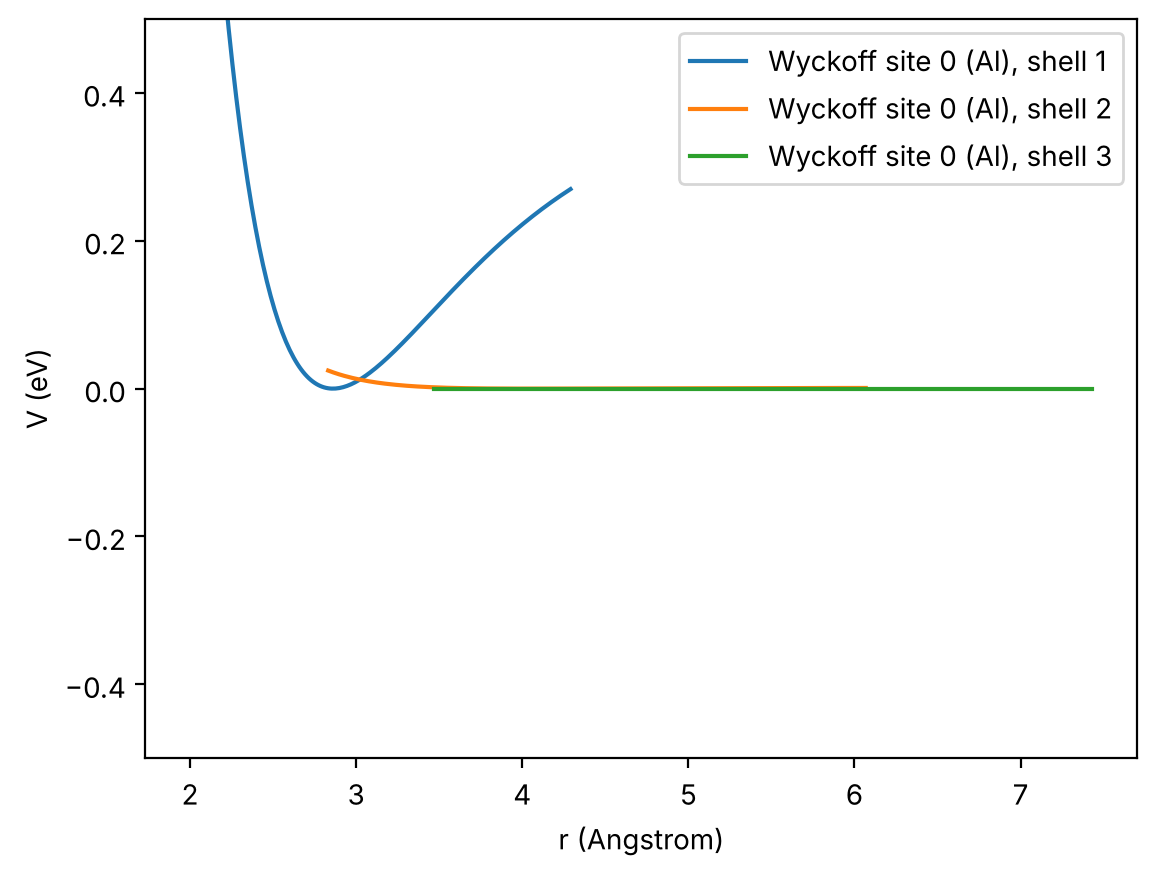

In [10]:
bonding_potentials = mf_morse.build_bonding_potentials(
    morse_params=morse_params
)

fig, ax = plt.subplots()
for wyckoff_site, data in bonding_potentials.items():
    for shell, potential in data["shells"].items():
        r_e = morse_params[wyckoff_site]["shells"][shell]["r_e"]
        r = np.linspace(0.7 * r_e, 1.5 * r_e, 200)
        bond_vectors = np.stack(
            [r, np.zeros_like(r), np.zeros_like(r)], axis=-1
        )
        ax.plot(
            r,
            potential(bond_vectors),
            label=(
                f"Wyckoff site {wyckoff_site} ({data['species']}), "
                f"shell {shell}"
            ),
        )

ax.set_xlabel("r (Angstrom)")
ax.set_ylabel("V (eV)")
ax.set_ylim(-0.5, 0.5)
ax.legend()
plt.show()